## Download, mosaic, clip, and align POLARIS soil pH raster (6-state extent)

In [2]:
import math
import os
import subprocess
import requests
import geopandas as gpd
import osmnx as ox
import rasterio
from rasterio.enums import Resampling
from shapely.geometry import box
import matplotlib.pyplot as plt

states = [
    "Ohio",
    "Michigan",
    "Indiana",
    "Pennsylvania",
    "Kentucky",
    "West Virginia",
]

# POLARIS soil pH configuration
# Statistics: "mean", "mode", "p50" (median), "p5", "p95"
# Depths (cm): "0_5", "5_15", "15_30", "30_60", "60_100", "100_200"
STAT = "mean"
DEPTH = "0_5"
BASE_URL = f"http://hydrology.cee.duke.edu/POLARIS/PROPERTIES/v1.0/ph/{STAT}/{DEPTH}"

DST_CRS = "EPSG:5070"
DST_NODATA = -9999.0  # Float32 nodata for continuous soil pH

WORK_DIR = "/kaggle/working"
TILE_DIR = os.path.join(WORK_DIR, f"polaris_ph_{STAT}_{DEPTH}_tiles")
os.makedirs(TILE_DIR, exist_ok=True)

In [3]:
# 1. Get 6-state bounding polygon and lock exact 30m-aligned EPSG:5070 bounds
ox.settings.cache_folder = os.path.join(WORK_DIR, "cache")

region_queries = [f"{state}, USA" for state in states]
regions_gdf = ox.geocode_to_gdf(region_queries)

# Keep WGS84 boundary for 1x1 degree tile intersection
boundary_4326 = regions_gdf.to_crs("EPSG:4326").union_all().buffer(0)

# Project to EPSG:5070 BEFORE unioning/buffering so geometry ops happen in meters
regions_5070 = regions_gdf.to_crs(DST_CRS)
master_boundary = regions_5070.union_all().buffer(0)

cutline_path = os.path.join(WORK_DIR, "six_state_cutline_5070.gpkg")
gpd.GeoDataFrame(geometry=[master_boundary], crs=DST_CRS).to_file(
    cutline_path, driver="GPKG"
)

# Exact same 30m-aligned bounding box logic as NLCD_raster_prep2.py
minx, miny, maxx, maxy = master_boundary.bounds
te_bounds = [
    str(int(minx // 30) * 30),
    str(int(miny // 30) * 30),
    str(int((maxx // 30) + 1) * 30),
    str(int((maxy // 30) + 1) * 30),
]
print(f"Locked 30m aligned bounds (EPSG:5070): {te_bounds}")

Locked 30m aligned bounds (EPSG:5070): ['429030', '1513980', '1781880', '2834850']


In [4]:
# 2. Download intersecting 1x1 degree POLARIS soil pH GeoTIFF tiles
min_lon, min_lat, max_lon, max_lat = boundary_4326.bounds
lat_range = range(math.floor(min_lat), math.floor(max_lat) + 1)
lon_range = range(math.floor(min_lon), math.floor(max_lon) + 1)

downloaded_tiles = []

for lat in lat_range:
    for lon in lon_range:
        tile_geom = box(lon, lat, lon + 1, lat + 1)
        if not boundary_4326.intersects(tile_geom):
            continue

        fname = f"lat{lat}{lat + 1}_lon{lon}{lon + 1}.tif"
        url = f"{BASE_URL}/{fname}"
        local_path = os.path.join(TILE_DIR, fname)

        if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
            downloaded_tiles.append(local_path)
            continue

        resp = requests.get(url, stream=True, timeout=60)
        if resp.status_code == 200:
            with open(local_path, "wb") as f:
                for chunk in resp.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
            downloaded_tiles.append(local_path)
            print(f"Downloaded {fname}")
        elif resp.status_code == 404:
            print(f"Skipped {fname} (404 - outside CONUS/water)")
        else:
            resp.raise_for_status()

if not downloaded_tiles:
    raise RuntimeError("No POLARIS tiles were downloaded; check network or URL.")

print(f"Total tiles ready for mosaic: {len(downloaded_tiles)}")

Downloaded lat3637_lon-90-89.tif
Downloaded lat3637_lon-89-88.tif
Downloaded lat3637_lon-88-87.tif
Downloaded lat3637_lon-87-86.tif
Downloaded lat3637_lon-86-85.tif
Downloaded lat3637_lon-85-84.tif
Downloaded lat3637_lon-84-83.tif
Downloaded lat3637_lon-83-82.tif
Downloaded lat3738_lon-90-89.tif
Downloaded lat3738_lon-89-88.tif
Downloaded lat3738_lon-88-87.tif
Downloaded lat3738_lon-87-86.tif
Downloaded lat3738_lon-86-85.tif
Downloaded lat3738_lon-85-84.tif
Downloaded lat3738_lon-84-83.tif
Downloaded lat3738_lon-83-82.tif
Downloaded lat3738_lon-82-81.tif
Downloaded lat3738_lon-81-80.tif
Downloaded lat3738_lon-80-79.tif
Downloaded lat3839_lon-89-88.tif
Downloaded lat3839_lon-88-87.tif
Downloaded lat3839_lon-87-86.tif
Downloaded lat3839_lon-86-85.tif
Downloaded lat3839_lon-85-84.tif
Downloaded lat3839_lon-84-83.tif
Downloaded lat3839_lon-83-82.tif
Downloaded lat3839_lon-82-81.tif
Downloaded lat3839_lon-81-80.tif
Downloaded lat3839_lon-80-79.tif
Downloaded lat3839_lon-79-78.tif
Downloaded

In [5]:
# 3. Build VRT mosaic, then clip, reproject, and align in a single GDAL pass
vrt_path = os.path.join(WORK_DIR, f"polaris_ph_{STAT}_{DEPTH}.vrt")
out_path = os.path.join(WORK_DIR, f"polaris_ph_{STAT}_{DEPTH}_clipped_reproj.tiff")

subprocess.run(
    ["gdalbuildvrt", "-overwrite", vrt_path, *downloaded_tiles],
    check=True,
    capture_output=True,
    text=True,
)

cmd = [
    "gdalwarp",
    "-overwrite",
    "-t_srs", DST_CRS,
    "-te", *te_bounds,           # Exact shared extent with NLCD rasters
    "-tr", "30", "30",           # Exact 30m x 30m resolution
    "-r", "bilinear",            # Continuous soil pH
    "-cutline", cutline_path,
    "-dstnodata", str(DST_NODATA),
    "-ot", "Float32",            # Preserve continuous pH decimals
    "-multi",
    "-wo", "NUM_THREADS=ALL_CPUS",
    "-co", "COMPRESS=LZW",
    "-co", "TILED=YES",
    "-co", "BLOCKXSIZE=512",
    "-co", "BLOCKYSIZE=512",
    vrt_path,
    out_path,
]

try:
    subprocess.run(cmd, check=True, capture_output=True, text=True)
    print(f"Successfully wrote {out_path}")
except subprocess.CalledProcessError as e:
    print("\nGDAL ERROR:")
    print(e.stderr)
    raise

# Clean up temporary cutline GeoPackage and VRT
for tmp in (cutline_path, vrt_path):
    if os.path.exists(tmp):
        os.remove(tmp)

Successfully wrote /kaggle/working/polaris_ph_mean_0_5_clipped_reproj.tiff


POLARIS pH (mean, 0_5 cm) | shape: (44029, 45095) | CRS: EPSG:5070 | dtype: float32 | nodata: -9999.0
Grid check passed: exact match with FctImp_clipped_reproj.tiff


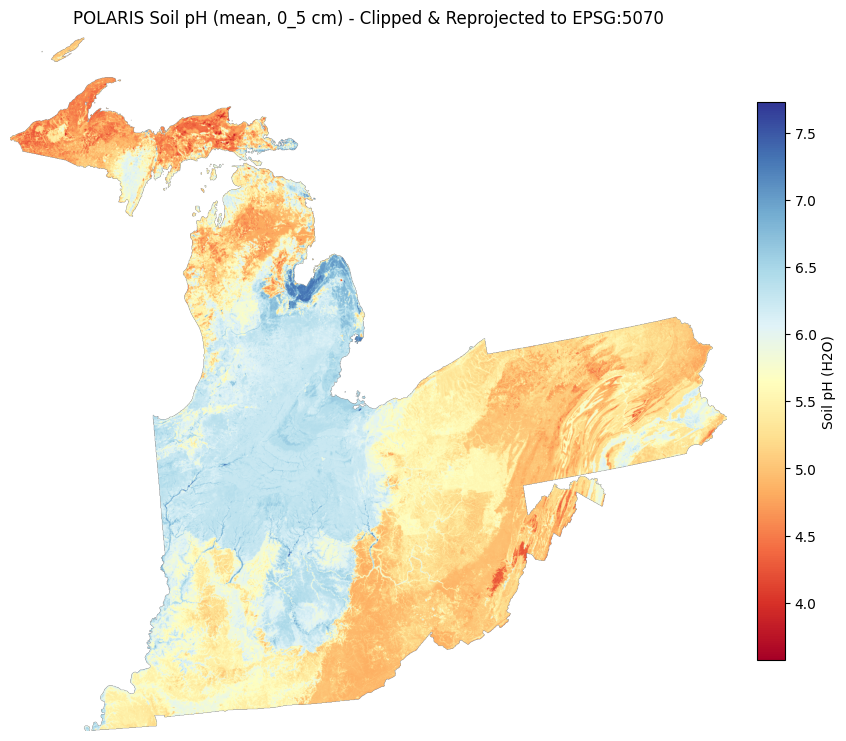

In [ ]:
# 4. Verify grid alignment (including against NLCD output if present) and plot
with rasterio.open(out_path) as src:
    print(
        f"POLARIS pH ({STAT}, {DEPTH} cm) | shape: {src.shape} | "
        f"CRS: {src.crs} | dtype: {src.dtypes[0]} | nodata: {src.nodata}"
    )

    # ref_nlcd = os.path.join(WORK_DIR, "FctImp_clipped_reproj.tiff")
    ref_nlcd = '/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff'
    if os.path.exists(ref_nlcd):
        with rasterio.open(ref_nlcd) as ref:
            assert src.shape == ref.shape, f"Shape mismatch: {src.shape} vs {ref.shape}"
            assert src.crs == ref.crs, f"CRS mismatch: {src.crs} vs {ref.crs}"
            assert src.transform == ref.transform, "Affine transform mismatch!"
            print(f"Grid check passed: exact match with {ref_nlcd}")

    max_size = 1500
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(image, cmap="RdYlBu")
plt.colorbar(im, ax=ax, fraction=0.036, pad=0.04, label="Soil pH (H2O)")
ax.set_title(f"POLARIS Soil pH ({STAT}, {DEPTH} cm) - Clipped & Reprojected to EPSG:5070")
ax.axis("off")
plt.show()